## 📓 Notebook 02: Boosting Theory — Single Tree

**Skills practiced:** `DecisionTreeClassifier`, inspecting misclassified rows, stratified train/val/test splits, plotting an XGBoost loss curve.

**Goal:** Build the shared split, then see boosting intuition first-hand: study one shallow tree's mistakes and watch a small boosted model's loss shrink tree by tree.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, classification_report


In [ ]:
df=pd.read_csv('../data/processed/Telco_customer_churn.csv')

x=df.drop(columns=['Churn'])
y=df.Churn

df.info()

  Missing TotalCharges: 11
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print('  Missing TotalCharges:', df["TotalCharges"].isna().sum())
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

In [4]:
x_temp,x_test,y_temp,y_test=train_test_split(x, y, stratify=y, test_size=0.2, random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_temp, y_temp, stratify=y_temp, test_size=0.15, random_state=42)

In [5]:
results = {}
cats=['gender','Partner','Dependents','PhoneService','MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaperlessBilling','PaymentMethod']

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop=None)
ohe.fit(x_train[cats])

for name, x in {'train_enc': x_train, 'test_enc': x_test, 'validate_enc': x_val}.items():    
    x_enc=pd.DataFrame(ohe.transform(x[cats]), columns=ohe.get_feature_names_out())
    results[name] = x.join(x_enc).drop(columns=cats)

In [6]:
x_train.to_csv('../data/processed/x_train.csv',index=False)
x_test.to_csv('../data/processed/x_test.csv',index=False)
x_val.to_csv('../data/processed/x_val.csv',index=False)
y_train.to_csv('../data/processed/y_train.csv',index=False)
y_test.to_csv('../data/processed/y_test.csv',index=False)
y_val.to_csv('../data/processed/y_val.csv',index=False)
results['train_enc'].to_csv('../data/processed/train_enc.csv',index=False)
results['test_enc'].to_csv('../data/processed/test_enc.csv',index=False)
results['validate_enc'].to_csv('../data/processed/validate_enc.csv',index=False)

In [7]:
DTC=DecisionTreeClassifier(max_depth=3)
DTC.fit(results['train_enc'], y_train)
preds = DTC.predict(results['test_enc'])

In [8]:
print(classification_report(y_test, preds))
print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, preds)}")

              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1035
           1       0.58      0.45      0.51       374

    accuracy                           0.77      1409
   macro avg       0.70      0.67      0.68      1409
weighted avg       0.76      0.77      0.76      1409

Root Mean Squared Error: 0.48027080130213257


In [9]:
wrong_mask = (y_test != preds)
x_test[wrong_mask].sample(10, random_state=42)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
6864,Female,1,No,No,3,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,25.30,77.75
4259,Female,0,No,No,3,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.60,59.75
4721,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.25,20.25
3510,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.25,576.70
2711,Female,0,Yes,Yes,28,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,One year,Yes,Bank transfer (automatic),90.10,2598.95
5871,Male,0,No,No,24,Yes,Yes,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.65,1400.55
6466,Male,0,No,No,18,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Mailed check,74.15,1387.00
3550,Male,0,No,No,32,Yes,No,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,96.20,3183.40
4078,Male,0,Yes,Yes,22,Yes,No,DSL,Yes,No,Yes,Yes,Yes,No,One year,Yes,Bank transfer (automatic),67.50,1544.05
5842,Female,0,No,No,13,Yes,Yes,DSL,Yes,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,78.75,995.35


most(8 out of 10 random samples) misclassified training rows are PhoneService month-to-month contracts with $25-$75 monthly charges

When a second tree trains miscalssified rows like those above gonna be spotted and where those gets blinds. when adding two predictions together second tree is gonna train on the pattern the first tree's error and reduce the error by repeating that instead of recreating the same tree errors. gradient boosting is automating the fitting on remaining error process. Which is gonna gradually shrink the overall error.

In [10]:
m=xgb.XGBClassifier(n_estimators=50, max_depth=3,random_state=42, n_jobs=-1,)
m.fit(results['train_enc'], y_train, eval_set=[(results['validate_enc'], y_val)])
xgb_preds=m.predict(results['test_enc'])

print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, xgb_preds)}")

[0]	validation_0-logloss:0.52414
[1]	validation_0-logloss:0.50009
[2]	validation_0-logloss:0.48626
[3]	validation_0-logloss:0.47310
[4]	validation_0-logloss:0.46519
[5]	validation_0-logloss:0.46034
[6]	validation_0-logloss:0.45742
[7]	validation_0-logloss:0.45351
[8]	validation_0-logloss:0.45271
[9]	validation_0-logloss:0.45009
[10]	validation_0-logloss:0.44953
[11]	validation_0-logloss:0.44836
[12]	validation_0-logloss:0.44839
[13]	validation_0-logloss:0.44814
[14]	validation_0-logloss:0.44729
[15]	validation_0-logloss:0.44686
[16]	validation_0-logloss:0.44695
[17]	validation_0-logloss:0.44707
[18]	validation_0-logloss:0.44754
[19]	validation_0-logloss:0.44771
[20]	validation_0-logloss:0.44856
[21]	validation_0-logloss:0.44853
[22]	validation_0-logloss:0.44839
[23]	validation_0-logloss:0.44899
[24]	validation_0-logloss:0.44821
[25]	validation_0-logloss:0.44799
[26]	validation_0-logloss:0.44849
[27]	validation_0-logloss:0.44872
[28]	validation_0-logloss:0.44895
[29]	validation_0-loglos

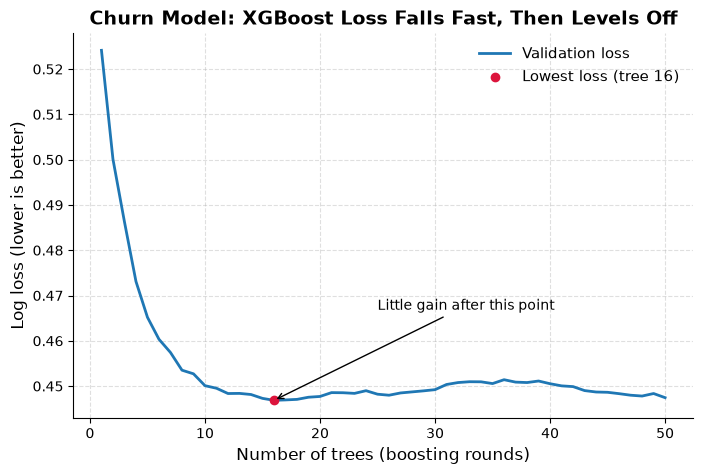

In [11]:
loss = m.evals_result()["validation_0"]["logloss"]
best_tree = loss.index(min(loss))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(loss) + 1), loss, color="#1f77b4", linewidth=2, label="Validation loss")
ax.scatter(best_tree + 1, loss[best_tree], color="crimson", zorder=3, label=f"Lowest loss (tree {best_tree + 1})")

ax.set_title("Churn Model: XGBoost Loss Falls Fast, Then Levels Off", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of trees (boosting rounds)", fontsize=12)
ax.set_ylabel("Log loss (lower is better)", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=11)
ax.annotate("Little gain after this point", xy=(best_tree + 1, loss[best_tree]),
            xytext=(25, loss[best_tree] + 0.02), arrowprops=dict(arrowstyle="->"))

fig.savefig("../outputs/figures/xgb_logloss.png", dpi=300, bbox_inches="tight")
plt.show()

The loss drops steeply over the first 16 trees because the early trees fix the biggest errors. After about tree 10, the curve flattens because the remaining residuals are small, so each new tree gains very little. The small bumps after that suggest the model has stopped learning useful patterns, so the extra trees add almost nothing.